# Exploratory Data Analysis (EDA)

Análisis exploratorio de los datasets utilizados en el proyecto DermVLM.

## Datasets
1. **HAM10000**: 10,015 imágenes dermatoscópicas, 7 categorías diagnósticas
2. **SkinCaRe**: ~7,041 pares imagen-texto (SkinCAP + SkinCoT)
3. **MM-Skin**: Pares imagen-texto + VQA
4. **HIBA**: Imágenes con metadatos de fototipo

In [1]:
import sys
sys.path.insert(0, '..')

import json
from pathlib import Path
from collections import Counter

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

DATA_DIR = Path('../data')
RAW_DIR = DATA_DIR / 'raw'

# Mapeo de acrónimos HAM10000 → nombre completo
# Fuente: Tschandl et al. 2018 (doi:10.7910/DVN/DBW86T)
#   mel   → Melanoma (maligno)
#   nv    → Melanocytic Nevus — lunar benigno (el más frecuente, ~67% del dataset)
#   bcc   → Basal Cell Carcinoma (carcinoma basocelular, maligno)
#   akiec → Actinic Keratosis / Intraepithelial Carcinoma (lesión queratinocítica)
#   bkl   → Benign Keratosis-like Lesion (queratosis seborreica, lentigo solar, etc.)
#   df    → Dermatofibroma (benigno)
#   vasc  → Vascular Lesion (angioma, granuloma piogénico, etc.)
HAM10000_DX_LABELS = {
    'mel':   'Melanoma (mel)',
    'nv':    'Melanocytic Nevus (nv)',
    'bcc':   'Basal Cell Carcinoma (bcc)',
    'akiec': 'Actinic Keratosis /\nIntraep. Carcinoma (akiec)',
    'bkl':   'Benign Keratosis-like (bkl)',
    'df':    'Dermatofibroma (df)',
    'vasc':  'Vascular Lesion (vasc)',
}

## 1. HAM10000

In [2]:
# Cargar metadata
# El archivo viene del Harvard Dataverse sin extensión .csv — se prueba con y sin extensión
ham_dir = RAW_DIR / 'HAM10000'

meta_path = ham_dir / 'HAM10000_metadata.csv'
if not meta_path.exists():
    meta_path = ham_dir / 'HAM10000_metadata'  # sin extensión, como viene del Dataverse

if not meta_path.exists():
    raise FileNotFoundError(
        f'No se encontró el archivo de metadata en {ham_dir}. '
        'Descargarlo del Harvard Dataverse y ubicarlo en data/raw/HAM10000/ (ver USAGE.md §2.1).'
    )

ham_meta = pd.read_csv(meta_path)
print(f'HAM10000: {len(ham_meta)} samples')
print(f'Columnas: {list(ham_meta.columns)}')
ham_meta.head()

HAM10000: 10015 samples
Columnas: ['lesion_id', 'image_id', 'dx', 'dx_type', 'age', 'sex', 'localization', 'dataset']


,lesion_id,image_id,dx,dx_type,age,sex,localization,dataset
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp,vidir_modern
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp,vidir_modern
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp,vidir_modern
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp,vidir_modern
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear,vidir_modern


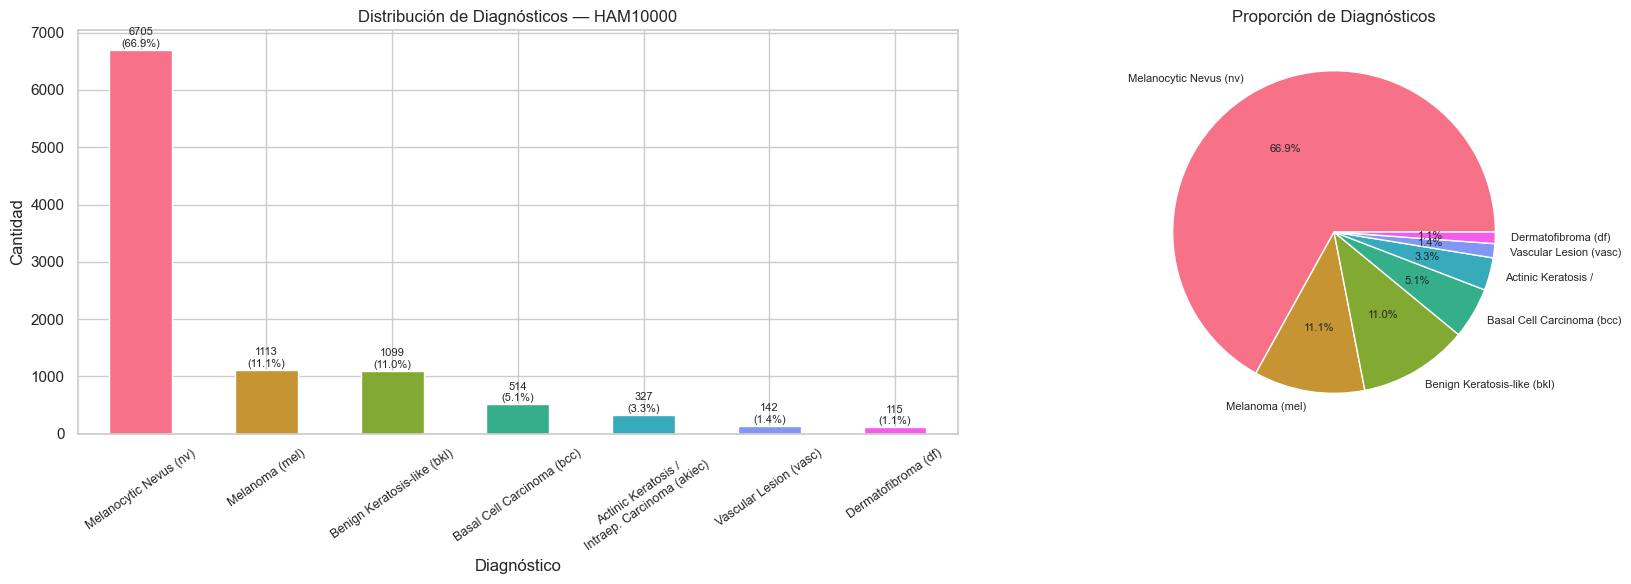


Referencia de acrónimos HAM10000:
  mel    → Melanoma (mel)
  nv     → Melanocytic Nevus (nv)
  bcc    → Basal Cell Carcinoma (bcc)
  akiec  → Actinic Keratosis / Intraep. Carcinoma (akiec)
  bkl    → Benign Keratosis-like (bkl)
  df     → Dermatofibroma (df)
  vasc   → Vascular Lesion (vasc)


In [3]:
# Distribución de diagnósticos
# Los valores de 'dx' en el CSV son acrónimos en minúsculas (ver HAM10000_DX_LABELS en la celda 1)
dx_counts = ham_meta['dx'].value_counts()

# Renombrar índice al nombre completo para los gráficos
dx_counts_named = dx_counts.rename(index=HAM10000_DX_LABELS)

fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# Bar chart con nombres completos
colors = sns.color_palette('husl', len(dx_counts_named))
dx_counts_named.plot(kind='bar', ax=axes[0], color=colors)
axes[0].set_title('Distribución de Diagnósticos — HAM10000')
axes[0].set_xlabel('Diagnóstico')
axes[0].set_ylabel('Cantidad')
axes[0].tick_params(axis='x', rotation=35, labelsize=9)

dx_pct = (dx_counts / len(ham_meta) * 100).round(1)
for i, (v, p) in enumerate(zip(dx_counts.values, dx_pct.values)):
    axes[0].text(i, v + 50, f'{v}\n({p}%)', ha='center', fontsize=8)

# Pie chart — etiquetas cortas para no saturar; leyenda con nombres completos
short_labels = [lbl.split('\n')[0] for lbl in dx_counts_named.index]  # primera línea
wedges, texts, autotexts = axes[1].pie(
    dx_counts.values,
    labels=short_labels,
    autopct='%1.1f%%',
    colors=colors,
    textprops={'fontsize': 8},
)
axes[1].set_title('Proporción de Diagnósticos')

plt.tight_layout()
plt.show()

# Imprimir la leyenda completa de acrónimos como referencia
print('\nReferencia de acrónimos HAM10000:')
for acr, full in HAM10000_DX_LABELS.items():
    label = full.replace('\n', ' ')
    print(f'  {acr:6s} → {label}')

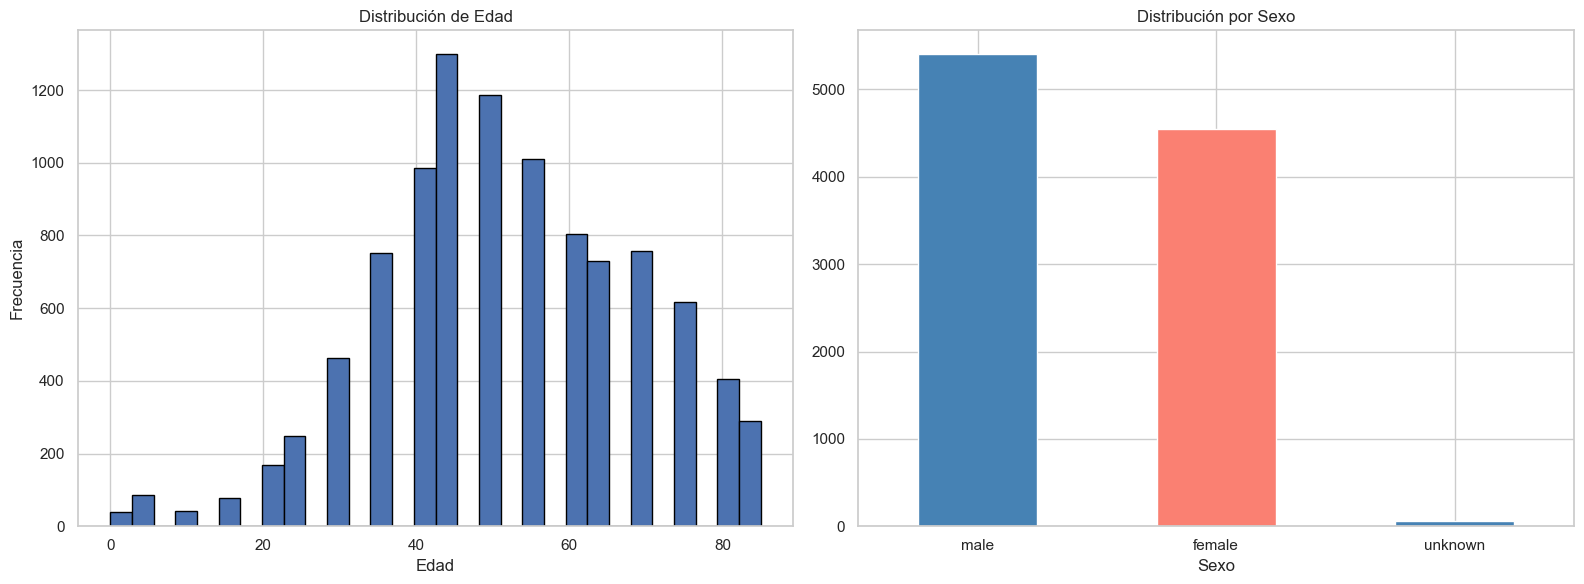

In [4]:
# Distribución por edad
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

ham_meta['age'].dropna().hist(bins=30, ax=axes[0], edgecolor='black')
axes[0].set_title('Distribución de Edad')
axes[0].set_xlabel('Edad')
axes[0].set_ylabel('Frecuencia')

# Distribución por sexo
sex_counts = ham_meta['sex'].value_counts()
sex_counts.plot(kind='bar', ax=axes[1], color=['steelblue', 'salmon'])
axes[1].set_title('Distribución por Sexo')
axes[1].set_xlabel('Sexo')
axes[1].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()

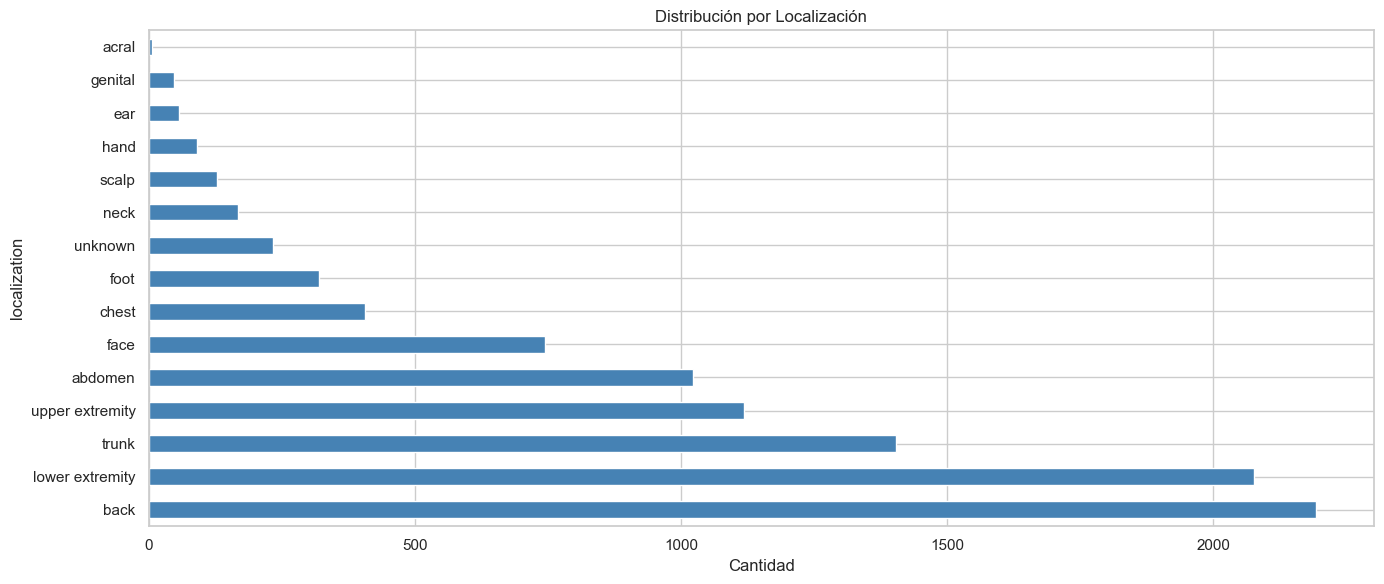

In [17]:
# Distribución por localización
fig, ax = plt.subplots(figsize=(14, 6))
loc_counts = ham_meta['localization'].value_counts()
loc_counts.plot(kind='barh', ax=ax, color='steelblue')
ax.set_title('Distribución por Localización')
ax.set_xlabel('Cantidad')
plt.tight_layout()
plt.show()

Imágenes encontradas: 10015


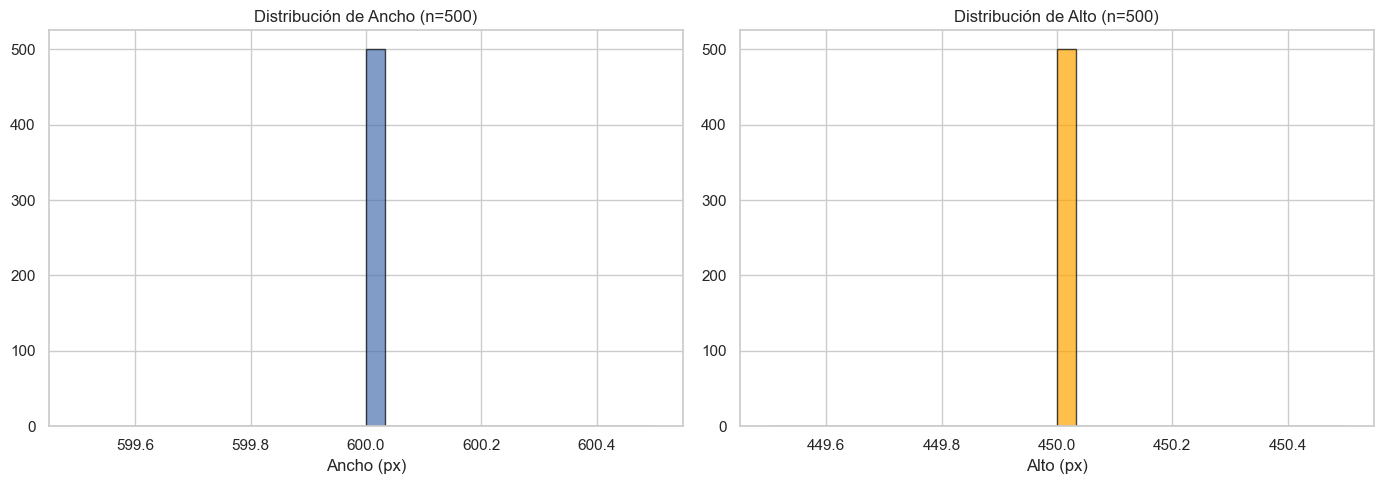

Ancho: min=600, max=600, median=600
Alto:  min=450, max=450, median=450


In [18]:
# Distribución de tamaños de imagen
# HAM10000 distribuye las imágenes en dos carpetas: part_1 y part_2
part1 = ham_dir / 'HAM10000_images_part_1'
part2 = ham_dir / 'HAM10000_images_part_2'

image_files = []
for folder in [part1, part2]:
    if folder.exists():
        image_files += list(folder.glob('*.jpg')) + list(folder.glob('*.png'))

# Fallback: si no se encontraron las carpetas de partes, buscar en la raíz y en images/
if not image_files:
    fallback = ham_dir / 'images' if (ham_dir / 'images').exists() else ham_dir
    image_files = list(fallback.glob('*.jpg')) + list(fallback.glob('*.png'))

print(f'Imágenes encontradas: {len(image_files)}')

if not image_files:
    print(
        'No se encontraron imágenes. Verificar que estén en:\n'
        f'  {part1}\n  {part2}\n'
        '(ver USAGE.md §2.2)'
    )
else:
    # Muestrear hasta 500 imágenes
    sample_files = image_files[:500]
    sizes = []
    for f in sample_files:
        try:
            img = Image.open(f)
            sizes.append(img.size)
        except Exception:
            pass

    if not sizes:
        print('No se pudieron leer imágenes de la muestra.')
    else:
        widths, heights = zip(*sizes)
        fig, axes = plt.subplots(1, 2, figsize=(14, 5))
        axes[0].hist(widths, bins=30, edgecolor='black', alpha=0.7)
        axes[0].set_title(f'Distribución de Ancho (n={len(sizes)})')
        axes[0].set_xlabel('Ancho (px)')
        axes[1].hist(heights, bins=30, edgecolor='black', alpha=0.7, color='orange')
        axes[1].set_title(f'Distribución de Alto (n={len(sizes)})')
        axes[1].set_xlabel('Alto (px)')
        plt.tight_layout()
        plt.show()

        print(f'Ancho: min={min(widths)}, max={max(widths)}, median={np.median(widths):.0f}')
        print(f'Alto:  min={min(heights)}, max={max(heights)}, median={np.median(heights):.0f}')

## 2. SkinCaRe

In [ ]:
# Cargar anotaciones
skincare_dir = RAW_DIR / 'skincare'
with open(skincare_dir / 'annotations.json', encoding='utf-8') as f:
    skincare_data = json.load(f)

print(f'SkinCaRe: {len(skincare_data)} samples')

# Distribución por source
sources = Counter(item.get('source', 'unknown') for item in skincare_data)
print(f'Sources: {dict(sources)}')

In [ ]:
# Longitud de textos
caption_lengths = [len(item.get('caption', '').split()) for item in skincare_data if item.get('caption')]
report_lengths = [len(item.get('report', '').split()) for item in skincare_data if item.get('report')]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

if caption_lengths:
    axes[0].hist(caption_lengths, bins=50, edgecolor='black', alpha=0.7)
    axes[0].set_title(f'Longitud de Captions (n={len(caption_lengths)})')
    axes[0].set_xlabel('Palabras')
    axes[0].axvline(np.median(caption_lengths), color='red', linestyle='--',
                    label=f'Mediana: {np.median(caption_lengths):.0f}')
    axes[0].legend()

if report_lengths:
    axes[1].hist(report_lengths, bins=50, edgecolor='black', alpha=0.7, color='green')
    axes[1].set_title(f'Longitud de Reportes CoT (n={len(report_lengths)})')
    axes[1].set_xlabel('Palabras')
    axes[1].axvline(np.median(report_lengths), color='red', linestyle='--',
                    label=f'Mediana: {np.median(report_lengths):.0f}')
    axes[1].legend()

plt.tight_layout()
plt.show()

In [ ]:
# Vocabulario clínico frecuente
from collections import Counter

all_text = ' '.join(
    item.get('caption', '') + ' ' + item.get('report', '')
    for item in skincare_data
).lower()

# Términos clínicos de interés
clinical_terms = [
    'melanoma', 'nevus', 'carcinoma', 'keratosis', 'dermatofibroma',
    'asymmetry', 'border', 'color', 'diameter', 'pigmentation',
    'ulceration', 'erythema', 'scaling', 'lesion', 'skin',
    'benign', 'malignant', 'dermoscopic', 'diagnosis',
]

term_freq = {term: all_text.count(term) for term in clinical_terms}
term_freq = dict(sorted(term_freq.items(), key=lambda x: x[1], reverse=True))

fig, ax = plt.subplots(figsize=(14, 6))
ax.barh(list(term_freq.keys()), list(term_freq.values()), color='teal')
ax.set_title('Frecuencia de Términos Clínicos en SkinCaRe')
ax.set_xlabel('Frecuencia')
plt.tight_layout()
plt.show()

## 3. HIBA

In [19]:
# Cargar metadata
hiba_dir = RAW_DIR / 'hiba'
hiba_meta = pd.read_csv(hiba_dir / 'metadata.csv')
print(f'HIBA: {len(hiba_meta)} samples')
print(f'Columnas: {list(hiba_meta.columns)}')
hiba_meta.head()

HIBA: 1616 samples
Columnas: ['isic_id', 'attribution', 'copyright_license', 'age_approx', 'anatom_site_general', 'anatom_site_special', 'benign_malignant', 'concomitant_biopsy', 'dermoscopic_type', 'diagnosis', 'diagnosis_1', 'diagnosis_2', 'diagnosis_3', 'diagnosis_confirm_type', 'family_hx_mm', 'fitzpatrick_skin_type', 'image_type', 'lesion_id', 'patient_id', 'personal_hx_mm', 'sex']


,isic_id,attribution,copyright_license,age_approx,anatom_site_general,anatom_site_special,benign_malignant,concomitant_biopsy,dermoscopic_type,diagnosis,...,diagnosis_2,diagnosis_3,diagnosis_confirm_type,family_hx_mm,fitzpatrick_skin_type,image_type,lesion_id,patient_id,personal_hx_mm,sex
0,ISIC_0079358,Hospital Italiano de Buenos Aires,CC-BY,35.0,anterior torso,NaN,benign,False,contact polarized,nevus,...,Benign melanocytic proliferations,Nevus,NaN,False,II,dermoscopic,IL_3989348,IP_9328831,False,female
1,ISIC_0086914,Hospital Italiano de Buenos Aires,CC-BY,55.0,upper extremity,NaN,malignant,True,contact polarized,basal cell carcinoma,...,Malignant adnexal epithelial proliferations - ...,Basal cell carcinoma,histopathology,False,II,dermoscopic,IL_9767756,IP_7506563,True,male
2,ISIC_0088904,Hospital Italiano de Buenos Aires,CC-BY,50.0,NaN,NaN,malignant,True,contact polarized,basal cell carcinoma,...,Malignant adnexal epithelial proliferations - ...,Basal cell carcinoma,histopathology,False,II,dermoscopic,IL_8711401,IP_0222733,False,female
3,ISIC_0094098,Hospital Italiano de Buenos Aires,CC-BY,65.0,posterior torso,NaN,malignant,True,NaN,melanoma,...,Malignant melanocytic proliferations (Melanoma),"Melanoma, NOS",histopathology,False,II,clinical: overview,IL_6961144,IP_1218261,True,male
4,ISIC_0095134,Hospital Italiano de Buenos Aires,CC-BY,70.0,anterior torso,NaN,malignant,True,contact polarized,melanoma,...,Malignant melanocytic proliferations (Melanoma),"Melanoma, NOS",histopathology,False,I,dermoscopic,IL_4530268,IP_8235588,True,female


Valores nulos en fitzpatrick_skin_type: 117


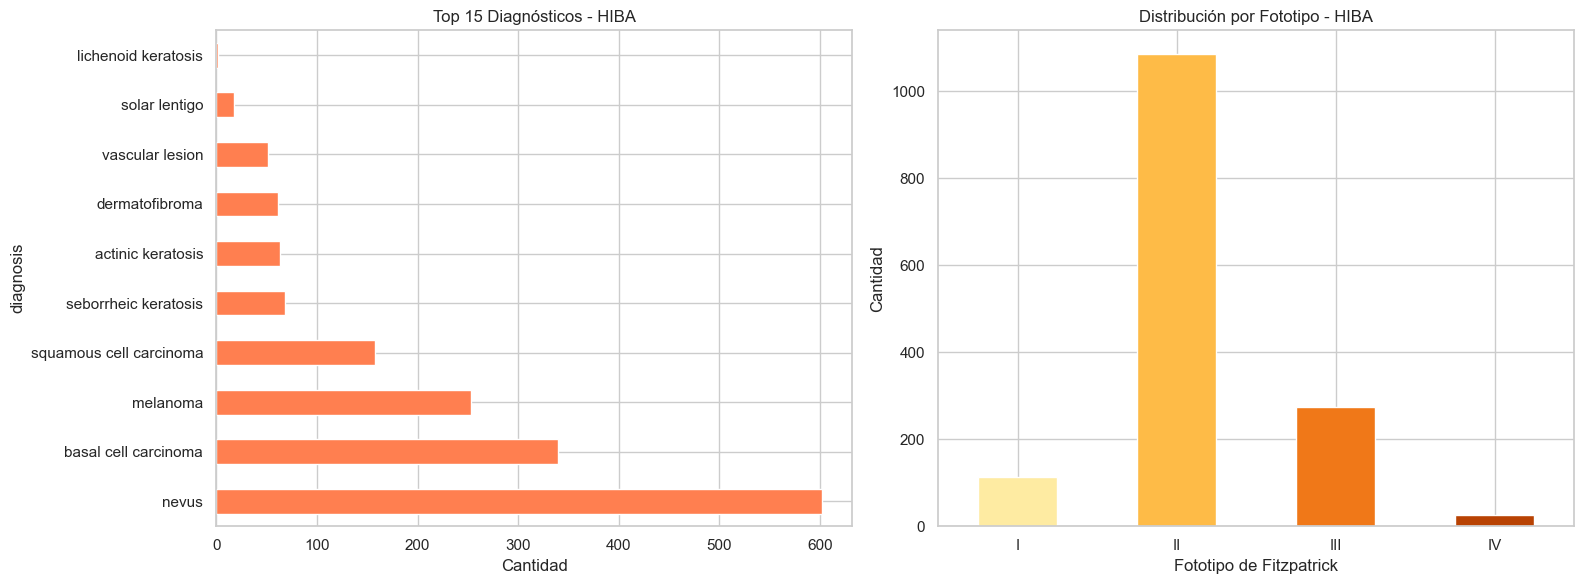

In [20]:
# Distribución por diagnóstico
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

dx_counts = hiba_meta['diagnosis'].value_counts()
dx_counts.head(15).plot(kind='barh', ax=axes[0], color='coral')
axes[0].set_title('Top 15 Diagnósticos - HIBA')
axes[0].set_xlabel('Cantidad')

# Distribución por fototipo (columna: fitzpatrick_skin_type)
fitz_col = 'fitzpatrick_skin_type'
if fitz_col in hiba_meta.columns:
    pt_counts = hiba_meta[fitz_col].dropna().value_counts().sort_index()
    pt_counts.plot(kind='bar', ax=axes[1], color=sns.color_palette('YlOrBr', len(pt_counts)))
    axes[1].set_title('Distribución por Fototipo - HIBA')
    axes[1].set_xlabel('Fototipo de Fitzpatrick')
    axes[1].set_ylabel('Cantidad')
    axes[1].tick_params(axis='x', rotation=0)
    print(f'Valores nulos en {fitz_col}: {hiba_meta[fitz_col].isna().sum()}')
else:
    print(f'Columna "{fitz_col}" no encontrada. Columnas disponibles: {list(hiba_meta.columns)}')

plt.tight_layout()
plt.show()

## 4. MM-Skin

In [21]:
# Cargar CSVs de MM-Skin
# caption.csv: 11090 filas — columnas: image, caption, modality, sex, age, cleaned_caption
# VQA.csv:     27259 filas — columnas: image, question, answer
# Los paths en 'image' tienen prefijo 'dataset/' que se stripea
mmskin_dir = RAW_DIR / 'MM-SkinQA'

caption_df = pd.read_csv(mmskin_dir / 'caption.csv')
vqa_df     = pd.read_csv(mmskin_dir / 'VQA.csv')

caption_df['filename'] = caption_df['image'].str.replace(r'^dataset/', '', regex=True)
vqa_df['filename']     = vqa_df['image'].str.replace(r'^dataset/', '', regex=True)

print(f'MM-Skin captions : {len(caption_df):>6} filas | {caption_df["filename"].nunique()} imágenes únicas')
print(f'MM-Skin VQA      : {len(vqa_df):>6} filas | {vqa_df["filename"].nunique()} imágenes')
print(f'\nColumnas caption : {list(caption_df.columns)}')
print(f'Columnas VQA     : {list(vqa_df.columns)}')
caption_df.head()

MM-Skin captions :  11090 filas | 11015 imágenes únicas
MM-Skin VQA      :  27259 filas | 9236 imágenes

Columnas caption : ['image', 'caption', 'modality', 'sex', 'age', 'cleaned_caption', 'filename']
Columnas VQA     : ['image', 'question', 'answer', 'filename']


,image,caption,modality,sex,age,cleaned_caption,filename
0,dataset/bk2_2_1.png,Cutaneousn/8 T-cell lymphoma. Multiple erythem...,skin,NaN,NaN,Cutaneousn/8 T-cell lymphoma. Multiple erythem...,bk2_2_1.png
1,dataset/bk2_2_2.png,Cutaneous/8T-cell lymphoma.Multiple plaques an...,skin,NaN,NaN,Cutaneous/8T-cell lymphoma.Multiple plaques an...,bk2_2_2.png
2,dataset/bk2_2_3.png,Cutaneous q/8 T-cell lymphoma. Erythematous pa...,skin,NaN,NaN,Cutaneous q/8 T-cell lymphoma. Erythematous pa...,bk2_2_3.png
3,dataset/bk2_2_4.png,Cutaneous/8 T-cell lymphoma.Erythematous tumor...,skin,NaN,NaN,Cutaneous/8 T-cell lymphoma.Erythematous tumor...,bk2_2_4.png
4,dataset/bk2_2_5.png,Cutaneousn/8 T-cell lymphoma.Large tumor on th...,skin,NaN,NaN,Cutaneousn/8 T-cell lymphoma.Large tumor on th...,bk2_2_5.png


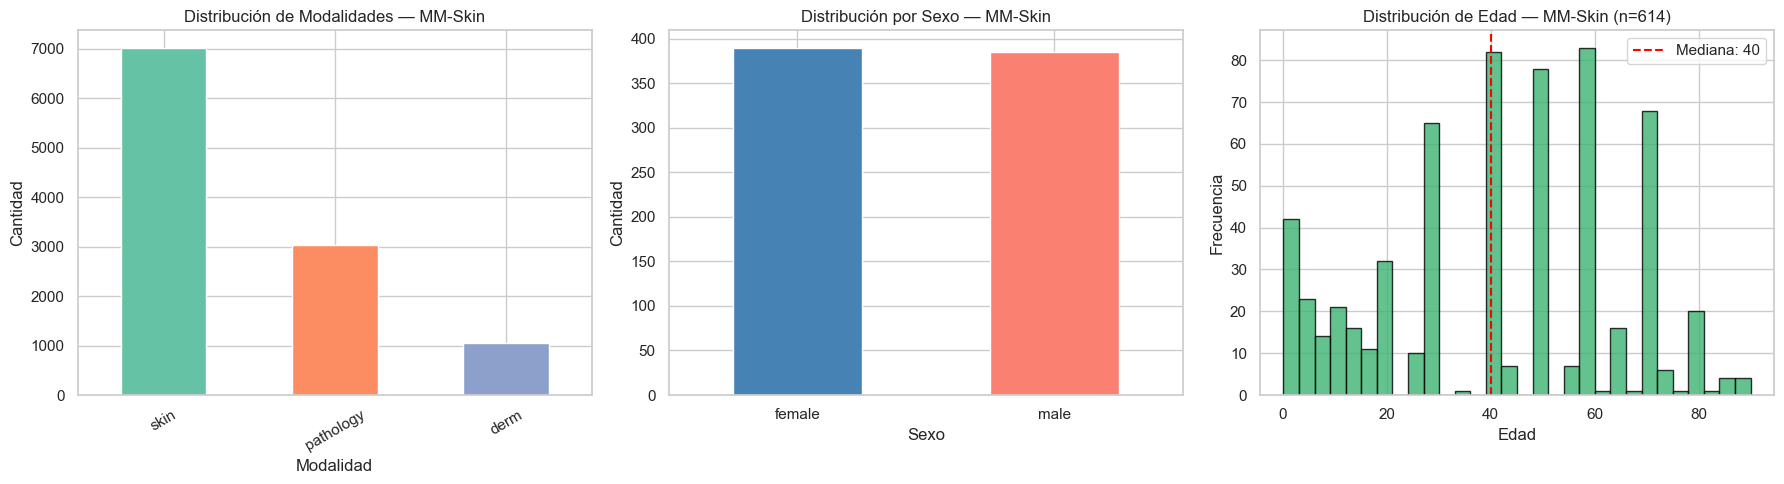

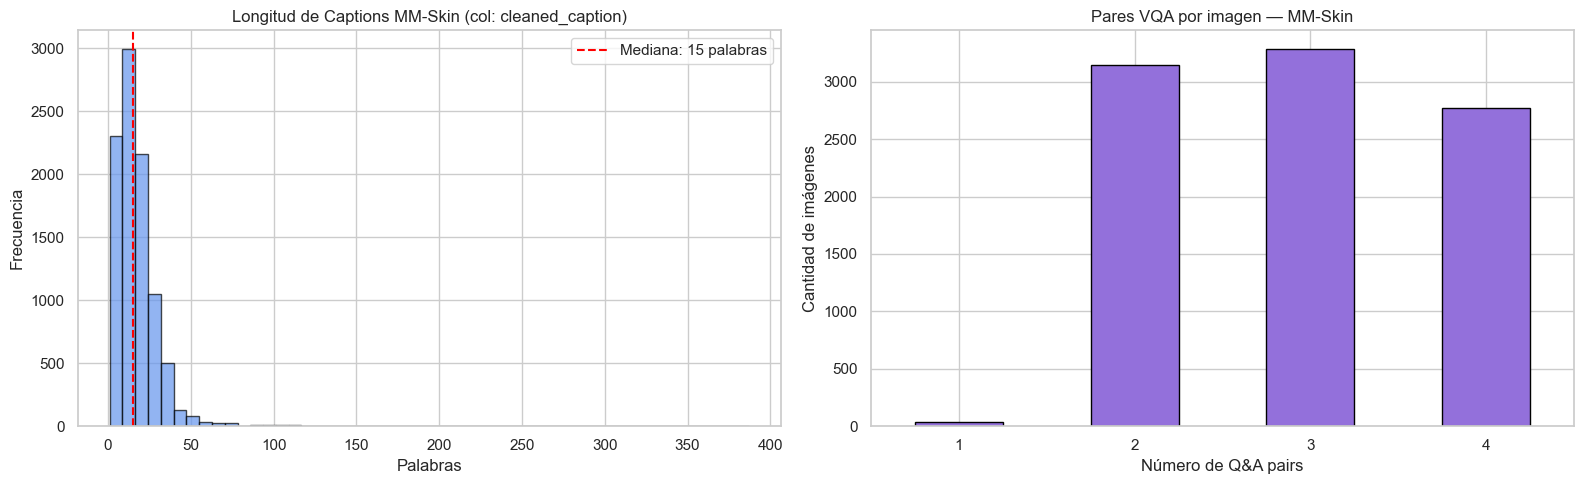

In [22]:
# Distribuciones demográficas y de modalidad
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Modalidad de imagen (dermoscopia, fotografía clínica, etc.)
if 'modality' in caption_df.columns:
    mod_counts = caption_df['modality'].value_counts()
    mod_counts.plot(kind='bar', ax=axes[0], color=sns.color_palette('Set2', len(mod_counts)))
    axes[0].set_title('Distribución de Modalidades — MM-Skin')
    axes[0].set_xlabel('Modalidad')
    axes[0].set_ylabel('Cantidad')
    axes[0].tick_params(axis='x', rotation=30)
else:
    axes[0].text(0.5, 0.5, 'Columna "modality" no disponible', ha='center', va='center')

# Sexo
if 'sex' in caption_df.columns:
    sex_counts = caption_df['sex'].dropna().value_counts()
    sex_counts.plot(kind='bar', ax=axes[1], color=['steelblue', 'salmon', 'gray'])
    axes[1].set_title('Distribución por Sexo — MM-Skin')
    axes[1].set_xlabel('Sexo')
    axes[1].tick_params(axis='x', rotation=0)
    axes[1].set_ylabel('Cantidad')
else:
    axes[1].text(0.5, 0.5, 'Columna "sex" no disponible', ha='center', va='center')

# Edad
if 'age' in caption_df.columns:
    ages = pd.to_numeric(caption_df['age'], errors='coerce').dropna()
    ages.hist(bins=30, ax=axes[2], edgecolor='black', alpha=0.8, color='mediumseagreen')
    axes[2].axvline(ages.median(), color='red', linestyle='--', label=f'Mediana: {ages.median():.0f}')
    axes[2].set_title(f'Distribución de Edad — MM-Skin (n={len(ages)})')
    axes[2].set_xlabel('Edad')
    axes[2].set_ylabel('Frecuencia')
    axes[2].legend()
else:
    axes[2].text(0.5, 0.5, 'Columna "age" no disponible', ha='center', va='center')

plt.tight_layout()
plt.show()

# Longitud de captions y pares VQA por imagen
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Preferir cleaned_caption si está disponible
text_col = 'cleaned_caption' if 'cleaned_caption' in caption_df.columns else 'caption'
cap_texts = caption_df[text_col].fillna(caption_df['caption'])
cap_lengths = cap_texts.dropna().str.split().apply(len)

cap_lengths.hist(bins=50, ax=axes[0], edgecolor='black', alpha=0.7, color='cornflowerblue')
axes[0].axvline(cap_lengths.median(), color='red', linestyle='--',
                label=f'Mediana: {cap_lengths.median():.0f} palabras')
axes[0].set_title(f'Longitud de Captions MM-Skin (col: {text_col})')
axes[0].set_xlabel('Palabras')
axes[0].set_ylabel('Frecuencia')
axes[0].legend()

# Número de pares VQA por imagen
vqa_per_image = vqa_df.groupby('filename').size()
vqa_per_image.value_counts().sort_index().plot(kind='bar', ax=axes[1],
                                                color='mediumpurple', edgecolor='black')
axes[1].set_title('Pares VQA por imagen — MM-Skin')
axes[1].set_xlabel('Número de Q&A pairs')
axes[1].set_ylabel('Cantidad de imágenes')
axes[1].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()

In [25]:
## 5. Resumen Comparativo
# Tabla resumen de todos los datasets
summary = pd.DataFrame({
    'Dataset': ['HAM10000', 'SkinCaRe', 'MM-Skin', 'HIBA'],
    'Tipo': ['Clasificación', 'Generación (img+texto)', 'Multimodal (captions + VQA)', 'Clasificación + fototipo'],
    'Samples': [
        len(ham_meta) if 'ham_meta' in dir() else '?',
        len(skincare_data) if 'skincare_data' in dir() else '?',
        f"{len(caption_df)} captions / {len(vqa_df)} Q&A" if 'caption_df' in dir() else '?',
        len(hiba_meta) if 'hiba_meta' in dir() else '?',
    ],
    'Fase': ['F1 + F2', 'F2', 'F2', 'F2'],
})
summary

,Dataset,Tipo,Samples,Fase
0,HAM10000,Clasificación,10015,F1 + F2
1,SkinCaRe,Generación (img+texto),?,F2
2,MM-Skin,Multimodal (captions + VQA),11090 captions / 27259 Q&A,F2
3,HIBA,Clasificación + fototipo,1616,F2
